# Análise Loja Aurora — 1º semestre de 2025 
**Integrantes:** Seu Nome 1, Nome 2, Nome 3.

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import json
import requests
from pathlib import Path

Path("limpeza_dedados").mkdir(exist_ok=True)
print("teste") 

teste


In [50]:
import os
import pandas as pd
from IPython.display import display, Markdown

# 1. CRIA A PASTA 'dados_tratados' 
os.makedirs("dados_tratados", exist_ok=True)

# 2. SALVAR ARQUIVOS
vendas.to_csv("dados_tratados/vendas_tratadas.csv", sep=";", index=False, encoding="utf-8-sig")
resumo.to_csv("dados_tratados/resumo_vendedores.csv", sep=";", index=False, encoding="utf-8-sig")
total_mes.to_csv("dados_tratados/total_mes.csv", sep=";", encoding="utf-8-sig")
total_regiao.to_csv("dados_tratados/total_regiao.csv", sep=";", encoding="utf-8-sig")
total_produto.to_csv("dados_tratados/total_produto.csv", sep=";", encoding="utf-8-sig")


display(Markdown(""" ### ✅ Sucesso! 
Os arquivos tratados foram salvos na pasta **`dados_tratados`**. """))

 ### ✅ Sucesso! 
Os arquivos tratados foram salvos na pasta **`dados_tratados`**. 

### Etapa 1 e 2 - Limpeza de Dados

In [39]:
import os
import pandas as pd
from IPython.display import display, Markdown

# PROCURA O ARQUIVO NA PASTA CERTA
pasta_certa = None
for raiz, pastas, arquivos in os.walk("."):
    if "vendas.csv" in arquivos:
        pasta_certa = raiz
        break

# LER O CSV
caminho_vendas = os.path.join(pasta_certa, "vendas.csv")
vendas = pd.read_csv(caminho_vendas, sep=";")

# 1. TIRAR O R$ E A VÍRGULA DO PREÇO, E CONVERTER PARA NÚMERO
vendas["preco_unitario"] = vendas["preco_unitario"].astype(str).str.replace("R$", "", regex=False).str.strip().str.replace(",", ".", regex=False)
vendas["preco_unitario"] = pd.to_numeric(vendas["preco_unitario"], errors="raise")

# 2. PADRONIZAR NOMES DOS VENDEDORES (SEM ESPAÇOS, INICIAIS MAIÚSCULAS)
vendas["vendedor"] = vendas["vendedor"].astype(str).str.strip().str.title()

# 3. DATA (DIA/MÊS/ANO) PARA DATA
vendas["data"] = pd.to_datetime(vendas["data"], format="%d/%m/%Y", errors="raise")

# 4. CONVERTER QUANTIDADE (E DESCARTAR OS INVÁLIDOS - ETAPA 2)
vendas["quantidade"] = pd.to_numeric(vendas["quantidade"].astype(str).str.strip(), errors="coerce")
linhas_invalidas = vendas["quantidade"].isna().sum()
vendas = vendas.dropna(subset=["quantidade"]).copy()
vendas["quantidade"] = vendas["quantidade"].astype(int)

# 5. CRIAR A COLUNA VALOR = QUANTIDADE X PREÇO
vendas["valor"] = vendas["quantidade"] * vendas["preco_unitario"]

# --- EXIBIÇÃO BONITA ---
texto_limpeza = f"""
---
#### Resultado da Limpeza (Etapas 1 e 2)
* **Preço:** Limpo (R$ e vírgulas removidos)
* **Vendedores:** Nomes padronizados
* **Datas:** Convertidas para o formato correto
* **Linhas descartadas (inválidas):** {linhas_invalidas}
* **Linhas válidas prontas:** {len(vendas)}
---
"""
display(Markdown(texto_limpeza))

# MOSTRAR A TABELA FORMATADA
tabela_estilizada = vendas.head()[["id_venda", "data", "vendedor", "regiao", "produto", "quantidade", "preco_unitario", "valor"]].style.format({
    "data": lambda x: x.strftime("%d/%m/%Y"),
    "preco_unitario": "R$ {:,.2f}",
    "valor": "R$ {:,.2f}"
})
display(tabela_estilizada)


---
#### Resultado da Limpeza (Etapas 1 e 2)
* **Preço:** Limpo (R$ e vírgulas removidos)
* **Vendedores:** Nomes padronizados
* **Datas:** Convertidas para o formato correto
* **Linhas descartadas (inválidas):** 6
* **Linhas válidas prontas:** 234
---


,id_venda,data,vendedor,regiao,produto,quantidade,preco_unitario,valor
0,V0032,02/01/2025,Carla Mendes,Nordeste,Calculadora Científica,1,R$ 89.90,R$ 89.90
1,V0166,02/01/2025,Elisa Prado,Nordeste,Agenda 2025,1,R$ 45.00,R$ 45.00
2,V0192,02/01/2025,Carla Mendes,Sul,Estojo Duplo,1,R$ 28.90,R$ 28.90
3,V0018,03/01/2025,Ana Souza,Sudeste,Calculadora Científica,4,R$ 94.40,R$ 377.60
4,V0142,03/01/2025,Carla Mendes,Nordeste,Mochila Escolar,3,R$ 129.90,R$ 389.70


### Etapa 3 - Regras de Negócio Funções.

In [14]:
# FUNÇÃO CALCULAR A COMISSÃO
def comissao(valor):
    if valor < 3000:
        return valor * 0.02
    elif valor < 6000:
        return valor * 0.05
    else:
        return valor * 0.08

# FUNÇÃO VER META
def situacao(atingimento):
    return "meta batida" if atingimento >= 100 else "abaixo da meta"

# TESTANDO FUNÇÕES
print("TESTE DE COMISSÃO:")
print("R$ 1.000 (2%):", comissao(1000))
print("R$ 4.000 (5%):", comissao(4000))
print("R$ 7.000 (8%):", comissao(7000))
print("\nTESTE DE SITUAÇÃO:")
print("Atingiu 105%:", situacao(105))
print("Atingiu 80%:", situacao(80))

TESTE DE COMISSÃO:
R$ 1.000 (2%): 20.0
R$ 4.000 (5%): 200.0
R$ 7.000 (8%): 560.0

TESTE DE SITUAÇÃO:
Atingiu 105%: meta batida
Atingiu 80%: abaixo da meta


### Etapa 4 - Estruturas de dados

In [16]:
# TOTAL POR VENDEDOR
total_vendedor = {}
for index, linha in vendas.iterrows():
    nome = linha["vendedor"]
    valor = linha["valor"]
    
    if nome in total_vendedor:
        total_vendedor[nome] += valor
    else:
        total_vendedor[nome] = valor

print("TOTAL POR VENDEDOR (DICIONÁRIO):")
for nome, total in total_vendedor.items():
    print(f"{nome}: R$ {total:,.2f}")

# MESES POR VENDEDOR
meses_vendedor = {}
for nome, grupo in vendas.groupby("vendedor"):
    # CRIA UM CONJUNTO COM OS MESES ÚNICOS EM QUE ELE VENDEU
    meses_vendedor[nome] = set(grupo["data"].dt.month)

# VERIFICANDO vencedor
todos_os_meses = {1, 2, 3, 4, 5, 6}
venderam_todos = set()
faltaram_algum = set()

for nome, meses in meses_vendedor.items():
    if meses == todos_os_meses:
        venderam_todos.add(nome)
    else:
        faltaram_algum.add(nome)

print("\nVENDERAM EM TODOS OS 6 MESES:")
print(venderam_todos)

print("\nFALTARAM EM ALGUM MÊS:")
print(faltaram_algum)

TOTAL POR VENDEDOR (DICIONÁRIO):
Carla Mendes: R$ 5,846.54
Elisa Prado: R$ 3,706.96
Ana Souza: R$ 8,139.23
Bruno Lima: R$ 3,487.18
Diego Rocha: R$ 4,019.14
Felipe Nunes: R$ 3,312.13

VENDERAM EM TODOS OS 6 MESES:
{'Diego Rocha', 'Carla Mendes', 'Felipe Nunes', 'Elisa Prado', 'Ana Souza', 'Bruno Lima'}

FALTARAM EM ALGUM MÊS:
set()


### Etapa 5 -  Resumos com pandas

In [52]:
# 1. TOTAL POR MÊS
vendas["mes"] = vendas["data"].dt.month
total_mes = vendas.groupby("mes")["valor"].sum().reset_index()

meses_dict = {1: "Janeiro", 2: "Fevereiro", 3: "Março", 4: "Abril", 5: "Maio", 6: "Junho"}
total_mes["mes"] = total_mes["mes"].map(meses_dict)
total_mes.columns = ["Mês", "Faturamento"]


# 2. TOTAL POR REGIÃO
total_regiao = vendas.groupby("regiao")["valor"].sum().sort_values(ascending=False).reset_index()
total_regiao.columns = ["Região", "Faturamento"]

# 3. TOTAL POR PRODUTO (TOP 5)
total_produto = vendas.groupby("produto")["valor"].sum().sort_values(ascending=False).head(5).reset_index()
total_produto.columns = ["Produto", "Faturamento"]


from IPython.display import display, Markdown

# 1. AGRUPAMENTO POR MÊS
vendas["mes"] = vendas["data"].dt.month
total_mes = vendas.groupby("mes")["valor"].sum().reset_index()

# TRADUZINDO O NÚMERO DO MÊS PARA O NOME
meses_dict = {1: "Janeiro", 2: "Fevereiro", 3: "Março", 4: "Abril", 5: "Maio", 6: "Junho"}
total_mes["mes"] = total_mes["mes"].map(meses_dict)
total_mes.columns = ["Mês", "Faturamento"]

# 2. AGRUPAMENTO POR REGIÃO
total_regiao = vendas.groupby("regiao")["valor"].sum().sort_values(ascending=False).reset_index()
total_regiao.columns = ["Região", "Faturamento"]

# 3. AGRUPAMENTO POR PRODUTO (TOP 5)
total_produto = vendas.groupby("produto")["valor"].sum().sort_values(ascending=False).head(5).reset_index()
total_produto.columns = ["Produto", "Faturamento"]



display(Markdown("### Faturamento por Mês"))
display(total_mes.style.format({"Faturamento": "R$ {:,.2f}"}).hide(axis="index"))

display(Markdown("### Faturamento por Região"))
display(total_regiao.style.format({"Faturamento": "R$ {:,.2f}"}).hide(axis="index"))

display(Markdown("### Top 5 Produtos"))
display(total_produto.style.format({"Faturamento": "R$ {:,.2f}"}).hide(axis="index"))





# 4. LER METAS
caminho_metas = os.path.join(pasta_certa, "metas.csv")
metas = pd.read_csv(caminho_metas, sep=";")
metas["vendedor"] = metas["vendedor"].astype(str).str.strip().str.title()

# 5. VENDAS POR VENDEDOR E METAS
resumo = vendas.groupby("vendedor")["valor"].sum().reset_index()
resumo = resumo.rename(columns={"valor": "total_vendido"})
resumo = resumo.merge(metas, on="vendedor", how="left")

# 6. CALCULAR ATINGIMENTO SITUAÇÃO E COMISSÃO 
resumo["atingimento_%"] = (resumo["total_vendido"] / resumo["meta_semestre"] * 100).round(1)
resumo["situacao"] = resumo["atingimento_%"].apply(situacao)
resumo["comissao"] = resumo["total_vendido"].apply(comissao)

print("--- TABELA FINAL DE METAS E COMISSÕES ---")
display(resumo)

### Faturamento por Mês

Mês,Faturamento
Janeiro,"R$ 6,991.56"
Fevereiro,"R$ 5,037.53"
Março,"R$ 4,215.90"
Abril,"R$ 4,731.67"
Maio,"R$ 4,360.16"
Junho,"R$ 3,174.36"


### Faturamento por Região

Região,Faturamento
Sudeste,"R$ 11,987.67"
Nordeste,"R$ 9,882.90"
Sul,"R$ 6,640.61"


### Top 5 Produtos

Produto,Faturamento
Mochila Escolar,"R$ 8,644.90"
Estojo Duplo,"R$ 6,313.00"
Calculadora Científica,"R$ 4,670.35"
Caderno 10 matérias,"R$ 2,565.80"
Agenda 2025,"R$ 2,511.00"


--- TABELA FINAL DE METAS E COMISSÕES ---


,vendedor,total_vendido,meta_semestre,atingimento_%,situacao,comissao
0,Ana Souza,8139.23,7500,108.5,meta batida,651.1384
1,Bruno Lima,3487.18,3500,99.6,abaixo da meta,174.3590
2,Carla Mendes,5846.54,5500,106.3,meta batida,292.3270
3,Diego Rocha,4019.14,4000,100.5,meta batida,200.9570
4,Elisa Prado,3706.96,5000,74.1,abaixo da meta,185.3480
5,Felipe Nunes,3312.13,3500,94.6,abaixo da meta,165.6065


### Etapa 6 - Gráficos

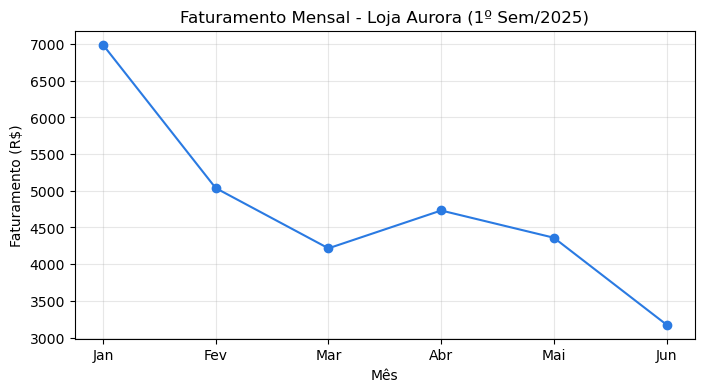

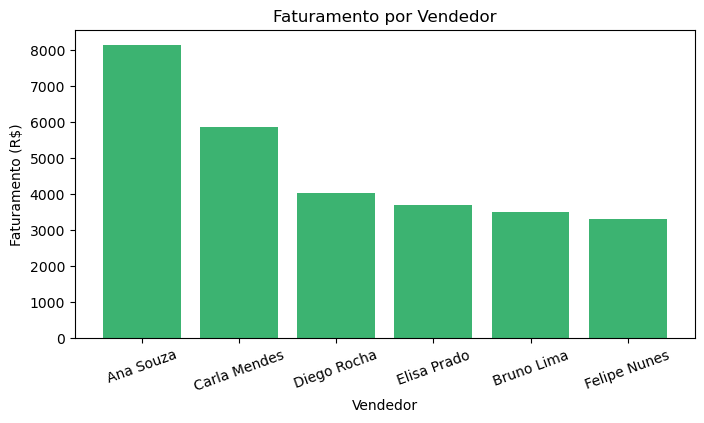

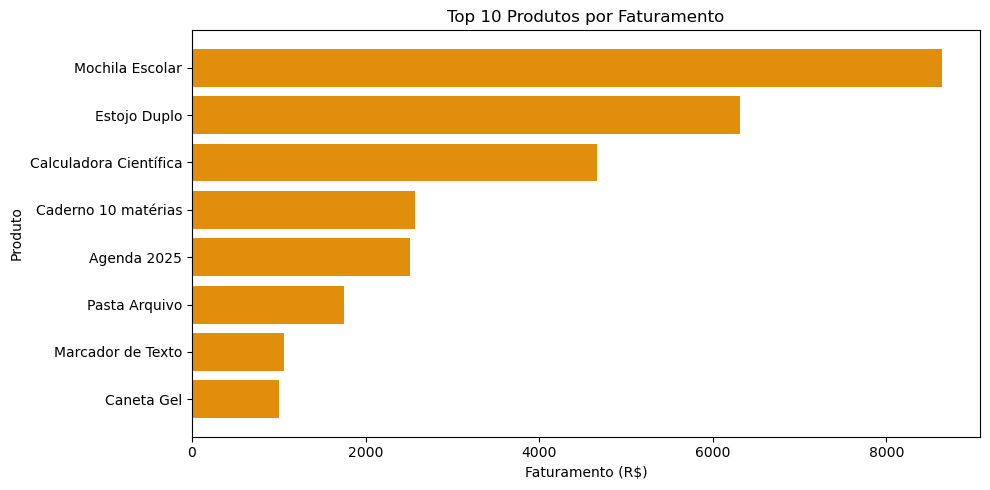

In [22]:
import matplotlib.pyplot as plt

# GRÁFICO 1: LINHA DO FATURAMENTO MENSAL
plt.figure(figsize=(8, 4))
meses_nomes = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun"]
plt.plot(meses_nomes, total_mes.values, marker="o", color="#2a7ae2")
plt.title("Faturamento Mensal - Loja Aurora (1º Sem/2025)")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.grid(alpha=0.3)
plt.show()

# GRÁFICO 2: BARRAS DE VENDEDORES
plt.figure(figsize=(8, 4))
resumo_sorted = resumo.sort_values("total_vendido", ascending=False)
plt.bar(resumo_sorted["vendedor"], resumo_sorted["total_vendido"], color="#3cb371")
plt.title("Faturamento por Vendedor")
plt.xlabel("Vendedor")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=20)
plt.show()

# GRÁFICO 3: BARRAS DE PRODUTOS (TOP 10)
plt.figure(figsize=(10, 5))
top_prod = vendas.groupby("produto")["valor"].sum().sort_values(ascending=False).head(10)
plt.barh(top_prod.index[::-1], top_prod.values[::-1], color="#e08e0b")
plt.title("Top 10 Produtos por Faturamento")
plt.xlabel("Faturamento (R$)")
plt.ylabel("Produto")
plt.tight_layout()
plt.show()

### Etapa 7 - API de feriados

In [33]:

import os
import json
import requests
import pandas as pd
from IPython.display import display, Markdown

# 1. API COM TIMEOUT
try:
    print("TENTANDO ACESSAR A API...")
    resposta = requests.get("https://brasilapi.com.br/api/feriados/v1/2025", timeout=5)
    resposta.raise_for_status()
    feriados = resposta.json()
    fonte = "API BrasilAPI (Internet)"
    
except Exception as erro:
    # 2. SE A API FALHAR, USA O ARQUIVO JSON DE RESERVA
    print(f"FALHA NA API ({erro}). USANDO ARQUIVO DE RESERVA...")
    caminho_backup = os.path.join(pasta_certa, "feriados_2025_backup.json")
    with open(caminho_backup, "r", encoding="utf-8") as arquivo:
        feriados = json.load(arquivo)
    fonte = "Arquivo de Reserva (Backup)"

datas_feriados = {pd.to_datetime(f["date"]).date() for f in feriados}
vendas["eh_feriado"] = vendas["data"].dt.date.isin(datas_feriados)


vendas_feriado = vendas[vendas["eh_feriado"]]
qtd_vendas_feriado = len(vendas_feriado)
faturamento_feriado = vendas_feriado["valor"].sum()

# 5. FORMATA O VALOR PARA O PADRÃO BRASILEIRO
valor_formatado = f"{faturamento_feriado:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


texto_resultado = f"""
---
### 📊 Resumo de Feriados
* **Fonte dos dados:** {fonte}
* **Total de feriados no ano:** {len(feriados)}
* **Vendas realizadas em feriados:** {qtd_vendas_feriado} vendas
* **Faturamento nesses dias:** **R$ {valor_formatado}**
---
"""
display(Markdown(texto_resultado))

tabela_feriados = vendas_feriado.sort_values("data")[["id_venda", "data", "vendedor", "produto", "valor"]]
tabela_bonita = tabela_feriados.style.format({
    "data": lambda x: x.strftime("%d/%m/%Y"),
    "valor": "R$ {:,.2f}"
})


display(tabela_bonita)

TENTANDO ACESSAR A API...



---
### 📊 Resumo de Feriados
* **Fonte dos dados:** API BrasilAPI (Internet)
* **Total de feriados no ano:** 14
* **Vendas realizadas em feriados:** 7 vendas
* **Faturamento nesses dias:** **R$ 859,40**
---


,id_venda,data,vendedor,produto,valor
148,V0141,18/04/2025,Carla Mendes,Calculadora Científica,R$ 80.91
151,V0127,21/04/2025,Elisa Prado,Caderno 10 matérias,R$ 68.24
159,V0007,01/05/2025,Carla Mendes,Marcador de Texto,R$ 39.50
160,V0024,01/05/2025,Carla Mendes,Estojo Duplo,R$ 28.90
161,V0035,01/05/2025,Elisa Prado,Mochila Escolar,R$ 545.60
162,V0115,01/05/2025,Ana Souza,Pasta Arquivo,R$ 62.50
163,V0123,01/05/2025,Felipe Nunes,Pasta Arquivo,R$ 33.75


### Etapa 8 - Dashboard

In [51]:
# 1. DEFINIR NOMES DOS ARQUIVOS E CAMINHOS
arquivo_vendas = "dados_tratados/vendas_tratadas.csv"
arquivo_resumo = "dados_tratados/resumo_vendedores.csv"
arquivo_mes = "dados_tratados/total_mes.csv"
arquivo_regiao = "dados_tratados/total_regiao.csv"
arquivo_produto = "dados_tratados/total_produto.csv"

# 2. SALVAR OS DATAFRAMES EM CSV 
vendas.to_csv(arquivo_vendas, sep=";", index=False, encoding="utf-8-sig")
resumo.to_csv(arquivo_resumo, sep=";", index=False, encoding="utf-8-sig")
total_mes.to_csv(arquivo_mes, sep=";", encoding="utf-8-sig")
total_regiao.to_csv(arquivo_regiao, sep=";", encoding="utf-8-sig")
total_produto.to_csv(arquivo_produto, sep=";", encoding="utf-8-sig")

print("✅ ARQUIVOS EXPORTADOS COM SUCESSO!")

✅ ARQUIVOS EXPORTADOS COM SUCESSO!
